# Problem 4.2: Evaluation of the trained masked-diffusion model (no retraining)

The training run (P4_b_discretediffusion) reached FID 44.9 (10k vs test) and **41.2 (50k vs train)** with 32 steps and
guidance w = 3.0. w = 3.0 was the **largest** guidance tested and clearly the best (w = 1.5 gave 51.6), so the optimum is
probably higher. This notebook loads `vqdiff_best.pt` and only changes the **sampler**:
1. guidance w = 3, 4, 5 (32 steps), then 6 if 5 is still better,
2. more unmasking steps (64) for the best w,
3. less / more randomness in the unmasking order (`noise` = 1 and 4 instead of 2),
4. final FID with the best setting: 50,000 generated vs. the 50,000 training images (standard), and 10k vs. test.

**Kaggle:** Add Input → **P4_b_discretediffusion** output (`vqdiff_best.pt`, `vqvae.pt`, `vq_tokens.pt`,
`cifar10_uint8.pt`). GPU T4 + Internet on → **Save Version → Save & Run All (Commit)**. Expected time: about 2–2.5 hours.
All numbers are written to `vqdiff_eval_results.json`.

## 1. Settings and input files

In [1]:
import os, glob, math, time, json
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

NOTEBOOK_START = time.time()
torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
use_amp = device.type == "cuda"

GROUPS, K, CODE_DIM = 10, 128, 8
MASK = K
NUM_CLASSES = 10
DIM, DEPTH, HEADS = 512, 12, 8
SAVE_DIR = "/kaggle/working"
os.makedirs(SAVE_DIR, exist_ok=True)
print("device:", device)


def find(name):
    hits = glob.glob(f"/kaggle/input/**/{name}", recursive=True)
    for p in [f"{SAVE_DIR}/{name}"] + hits:
        if os.path.exists(p):
            return p
    return None


for name in ["vqvae.pt", "vq_tokens.pt", "cifar10_uint8.pt", "vqdiff_best.pt"]:
    print(f"{name:<18} -> {find(name)}")
assert find("vqdiff_best.pt"), "vqdiff_best.pt not found: add the P4_b_discretediffusion output as input"
assert find("vqvae.pt") and find("vq_tokens.pt"), "vqvae.pt / vq_tokens.pt not found"

device: cuda
vqvae.pt           -> /kaggle/input/notebooks/rachdewanjee/p4-b-discretediffusion/vqvae.pt
vq_tokens.pt       -> /kaggle/input/notebooks/rachdewanjee/p4-b-discretediffusion/vq_tokens.pt
cifar10_uint8.pt   -> /kaggle/input/notebooks/rachdewanjee/p4-b-discretediffusion/cifar10_uint8.pt
vqdiff_best.pt     -> /kaggle/input/notebooks/rachdewanjee/p4-b-discretediffusion/vqdiff_best.pt


## 2. CIFAR-10

In [2]:
cifar = torch.load(find("cifar10_uint8.pt"))
to_float = lambda x: x.to(device).float().div(255)
print("loaded CIFAR-10")

loaded CIFAR-10


## 3. The 4.1 VQ-VAE (same classes as in training)

In [3]:
def block(c_in, c_out):
    return nn.Sequential(nn.Conv2d(c_in, c_out, 3, padding=1), nn.BatchNorm2d(c_out), nn.ReLU())


class GroupedVQ(nn.Module):
    def __init__(self, groups, k, dim, decay=0.99, eps=1e-5):
        super().__init__()
        self.G, self.K, self.d = groups, k, dim
        self.register_buffer("embed", torch.randn(groups, k, dim))
        self.register_buffer("embed_avg", self.embed.clone())
        self.register_buffer("cluster_size", torch.ones(groups, k))
        self.register_buffer("initted", torch.tensor(False))

    def forward(self, z):     # inference only here: nearest code per group
        B, _, H, W = z.shape
        z = z.float().view(B, self.G, self.d, H, W).permute(1, 0, 3, 4, 2).reshape(self.G, -1, self.d)
        dist = (z ** 2).sum(-1, keepdim=True) - 2 * z @ self.embed.transpose(1, 2) + (self.embed ** 2).sum(-1)[:, None]
        idx = dist.argmin(-1)
        return idx.view(self.G, B, H, W).permute(1, 0, 2, 3)

    def lookup(self, idx):
        B, G, H, W = idx.shape
        q = torch.stack([self.embed[g][idx[:, g]] for g in range(G)], 1)
        return q.permute(0, 1, 4, 2, 3).reshape(B, G * self.d, H, W)


class ResBlock(nn.Module):
    def __init__(self, c):
        super().__init__()
        self.net = nn.Sequential(nn.ReLU(), nn.Conv2d(c, c, 3, padding=1), nn.BatchNorm2d(c),
                                 nn.ReLU(), nn.Conv2d(c, c, 1), nn.BatchNorm2d(c))

    def forward(self, x):
        return x + self.net(x)


class VQVAE(nn.Module):
    def __init__(self):
        super().__init__()
        latent = GROUPS * CODE_DIM
        self.encoder = nn.Sequential(
            block(3, 64),
            nn.Conv2d(64, 128, 4, stride=2, padding=1), nn.BatchNorm2d(128), nn.ReLU(),
            block(128, 128),
            nn.Conv2d(128, 256, 4, stride=2, padding=1), nn.BatchNorm2d(256), nn.ReLU(),
            ResBlock(256), ResBlock(256), nn.ReLU(),
            nn.Conv2d(256, latent, 1),
        )
        self.vq = GroupedVQ(GROUPS, K, CODE_DIM)
        self.decoder = nn.Sequential(
            nn.Conv2d(latent, 256, 3, padding=1), nn.BatchNorm2d(256),
            ResBlock(256), ResBlock(256), nn.ReLU(),
            nn.ConvTranspose2d(256, 128, 4, stride=2, padding=1), nn.BatchNorm2d(128), nn.ReLU(),
            block(128, 128),
            nn.ConvTranspose2d(128, 64, 4, stride=2, padding=1), nn.BatchNorm2d(64), nn.ReLU(),
            nn.Conv2d(64, 3, 3, padding=1),
            nn.Sigmoid(),
        )


vq = VQVAE().to(device)
vq.load_state_dict(torch.load(find("vqvae.pt"), map_location=device))
vq.eval()


@torch.no_grad()
def encode(imgs_uint8):
    return torch.cat([vq.vq(vq.encoder(to_float(imgs_uint8[i:i + 500]))).cpu() for i in range(0, len(imgs_uint8), 500)])


@torch.no_grad()
def decode(tok):
    return torch.cat([vq.decoder(vq.vq.lookup(tok[i:i + 500].long().to(device))).cpu() for i in range(0, len(tok), 500)])

## 4. Test tokens (for the reconstruction FID)

In [4]:
saved = torch.load(find("vq_tokens.pt"))
test_tok = saved["test"].long()
check = encode(cifar["test_x"][:1000])
print(f"re-encoded vs saved test tokens: {100 * (check == test_tok[:1000]).float().mean():.2f}% identical")

re-encoded vs saved test tokens: 100.00% identical


## 5. The denoising Transformer, loaded from `vqdiff_best.pt`

In [5]:
class Denoiser(nn.Module):
    def __init__(self, dim=DIM, depth=DEPTH, heads=HEADS):
        super().__init__()
        self.tok_emb = nn.Embedding(GROUPS * (K + 1), dim)         # separate table per codebook
        self.pos_emb = nn.Parameter(torch.zeros(1, 64, dim))
        self.time_mlp = nn.Sequential(nn.Linear(1, dim), nn.SiLU(), nn.Linear(dim, dim))
        self.label_emb = nn.Embedding(NUM_CLASSES + 1, dim)
        layer = nn.TransformerEncoderLayer(dim, heads, 4 * dim, dropout=0.1, activation="gelu",
                                           batch_first=True, norm_first=True)
        self.transformer = nn.TransformerEncoder(layer, depth, enable_nested_tensor=False)
        self.norm = nn.LayerNorm(dim)
        self.head = nn.Linear(dim, GROUPS * K)
        nn.init.normal_(self.pos_emb, std=0.02)
        self.register_buffer("offset", torch.arange(GROUPS) * (K + 1))

    def forward(self, x, t, y):
        # x: (B, 10, 8, 8) values 0..128 (128 = MASK); t: (B,) mask ratio; y: (B,) labels 0..10
        B = x.shape[0]
        h = self.tok_emb(x.flatten(2).transpose(1, 2) + self.offset).sum(2)        # (B, 64, dim)
        h = h + self.pos_emb + (self.time_mlp(t.view(B, 1)) + self.label_emb(y))[:, None]
        h = self.norm(self.transformer(h))
        logits = self.head(h).view(B, 64, GROUPS, K)
        return logits.permute(0, 3, 2, 1).reshape(B, K, GROUPS, 8, 8)              # (B, 128, 10, 8, 8)


best = torch.load(find("vqdiff_best.pt"), map_location=device)
ema = Denoiser().to(device).eval().requires_grad_(False)
ema.load_state_dict(best["ema"])
print(f"loaded vqdiff_best.pt: epoch {best['epoch']}, quick FID {best['quick_fid']:.1f}, w = {best['w']}")

loaded vqdiff_best.pt: epoch 150, quick FID 47.5, w = 3.0


## 6. Sampler (same as training; `steps`, `w` and `noise` are the settings that are tuned)

In [6]:
@torch.no_grad()
def sample(net, labels, steps=32, w=2.0, temperature=1.0, noise=2.0):
    net.eval()
    n = len(labels)
    y = labels.to(device)
    y_null = torch.full_like(y, NUM_CLASSES)
    x = torch.full((n, GROUPS, 8, 8), MASK, device=device)
    N = GROUPS * 64
    for s in range(1, steps + 1):
        is_masked = x == MASK
        t = is_masked.float().flatten(1).mean(1)
        with torch.autocast("cuda", dtype=torch.float16, enabled=use_amp):
            lc, lu = net(torch.cat([x, x]), torch.cat([t, t]), torch.cat([y, y_null])).float().chunk(2)
        logits = (lu + w * (lc - lu)) / temperature                                   # (n, 128, 10, 8, 8)
        logp = F.log_softmax(logits, dim=1)
        guess = torch.distributions.Categorical(logits=logits.permute(0, 2, 3, 4, 1)).sample()   # (n, 10, 8, 8)
        conf = torch.gather(logp, 1, guess[:, None]).squeeze(1)
        gumbel = -torch.log(-torch.log(torch.rand_like(conf).clamp(1e-9, 1 - 1e-9)))
        conf = conf + noise * (1 - s / steps) * gumbel
        conf = torch.where(is_masked, conf, torch.full_like(conf, float("inf")))        # fixed tokens stay fixed
        x = torch.where(is_masked, guess, x)
        n_keep_masked = int(N * math.cos(math.pi / 2 * s / steps))
        if n_keep_masked > 0:
            lowest = conf.flatten(1).topk(n_keep_masked, dim=1, largest=False).indices
            x = x.flatten(1).scatter(1, lowest, MASK).view_as(x)
    assert (x != MASK).all()
    return x.cpu()


def balanced_labels(n):
    return torch.arange(n) % NUM_CLASSES

## 7. FID setup

In [7]:
!pip -q install torchmetrics[image]
from torchmetrics.image.fid import FrechetInceptionDistance

to_uint8 = lambda imgs: (imgs.clamp(0, 1) * 255).to(torch.uint8)
fid = FrechetInceptionDistance(feature=2048, reset_real_features=False).to(device)
for i in range(0, 10000, 500):
    fid.update(cifar["test_x"][i:i + 500].to(device), real=True)


def fid_of(fake_imgs):
    fid.reset()
    for i in range(0, len(fake_imgs), 500):
        fid.update(to_uint8(fake_imgs[i:i + 500]).to(device), real=False)
    return fid.compute().item()


def gen_images(n, steps, w, noise, seed=3):
    torch.manual_seed(seed)
    labels = balanced_labels(n)
    tok = torch.cat([sample(ema, labels[i:i + 500], steps=steps, w=w, noise=noise) for i in range(0, n, 500)])
    return decode(tok)


results = {}
def save_results():
    with open(f"{SAVE_DIR}/vqdiff_eval_results.json", "w") as f:
        json.dump(results, f, indent=2)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 85.6/85.6 kB 3.3 MB/s eta 0:00:00


Downloading: "https://github.com/toshas/torch-fidelity/releases/download/v0.2.0/weights-inception-2015-12-05-6726825d.pth" to /root/.cache/torch/hub/checkpoints/weights-inception-2015-12-05-6726825d.pth
100%|██████████| 91.2M/91.2M [00:00<00:00, 381MB/s]


## 8. Sampler sweep (5,000 images vs. the 10,000 test images, same seed for every setting)
The first setting (32 steps, w = 3, noise = 2) is the training sampler, for comparison.

In [8]:
N_SWEEP = 5000
sweep = {}
def run(steps, w, noise):
    if (steps, w, noise) in sweep:
        return sweep[(steps, w, noise)]
    t0 = time.time()
    v = fid_of(gen_images(N_SWEEP, steps, w, noise))
    sweep[(steps, w, noise)] = v
    results[f"sweep5k_steps{steps}_w{w}_noise{noise}"] = v
    save_results()
    print(f"steps {steps:3d} | w {w} | noise {noise} -> FID {v:.1f}  ({time.time() - t0:.0f}s)")
    return v

# 1) guidance strength
for w in [3.0, 4.0, 5.0]:
    run(32, w, 2.0)
if sweep[(32, 5.0, 2.0)] < sweep[(32, 4.0, 2.0)]:
    run(32, 6.0, 2.0)
W = min((k for k in sweep), key=sweep.get)[1]

# 2) more unmasking steps
run(64, W, 2.0)
STEPS = 64 if sweep[(64, W, 2.0)] < sweep[(32, W, 2.0)] else 32

# 3) randomness of the unmasking order
for noise in [1.0, 4.0]:
    run(STEPS, W, noise)

STEPS, W, NOISE = min(sweep, key=sweep.get)
results["best_sampler"] = {"steps": STEPS, "w": W, "noise": NOISE}
save_results()
print(f"\nbest sampler: steps {STEPS}, w {W}, noise {NOISE}  (5k FID {sweep[(STEPS, W, NOISE)]:.1f})")

steps  32 | w 3.0 | noise 2.0 -> FID 47.5  (202s)
steps  32 | w 4.0 | noise 2.0 -> FID 45.5  (200s)
steps  32 | w 5.0 | noise 2.0 -> FID 44.3  (200s)
steps  32 | w 6.0 | noise 2.0 -> FID 45.0  (201s)
steps  64 | w 5.0 | noise 2.0 -> FID 48.0  (375s)
steps  32 | w 5.0 | noise 1.0 -> FID 59.0  (199s)
steps  32 | w 5.0 | noise 4.0 -> FID 36.2  (201s)

best sampler: steps 32, w 5.0, noise 4.0  (5k FID 36.2)


## 9. Final FID
- **Standard protocol:** 50,000 generated images (5,000 per class) vs. the 50,000 CIFAR-10 training images.
- **10k protocol:** the first 10,000 of those images vs. the 10,000 test images.

In [9]:
t0 = time.time()
fake = gen_images(50000, STEPS, W, NOISE, seed=0)
print(f"generated 50,000 images in {(time.time() - t0) / 60:.0f} min")

fid_train = FrechetInceptionDistance(feature=2048).to(device)
for i in range(0, 50000, 500):
    fid_train.update(cifar["train_x"][i:i + 500].to(device), real=True)
    fid_train.update(to_uint8(fake[i:i + 500]).to(device), real=False)
fid_50k = fid_train.compute().item()
fid_10k = fid_of(fake[:10000])
recon_fid = fid_of(decode(test_tok))

results.update({"final_fid_50k_gen_vs_50k_train": fid_50k, "final_fid_10k_gen_vs_10k_test": fid_10k,
                "vqvae_recon_fid_10k_test": recon_fid})
save_results()

print()
print(f"VQ-VAE recon FID (ceiling, 10k test):        {recon_fid:6.1f}")
print(f"FID 50k generated vs 50k CIFAR-10 train:     {fid_50k:6.1f}   {'< 40 MET' if fid_50k < 40 else '>= 40 NOT MET'}")
print(f"FID 10k generated vs 10k CIFAR-10 test:      {fid_10k:6.1f}   {'< 40 MET' if fid_10k < 40 else '>= 40 NOT MET'}")
print(f"Sampler: {STEPS} unmasking steps, guidance w = {W}, noise = {NOISE}")

generated 50,000 images in 29 min

VQ-VAE recon FID (ceiling, 10k test):           8.0
FID 50k generated vs 50k CIFAR-10 train:       29.8   < 40 MET
FID 10k generated vs 10k CIFAR-10 test:        33.6   < 40 MET
Sampler: 32 unmasking steps, guidance w = 5.0, noise = 4.0


## 10. Generated images with the best sampler (one row per class)

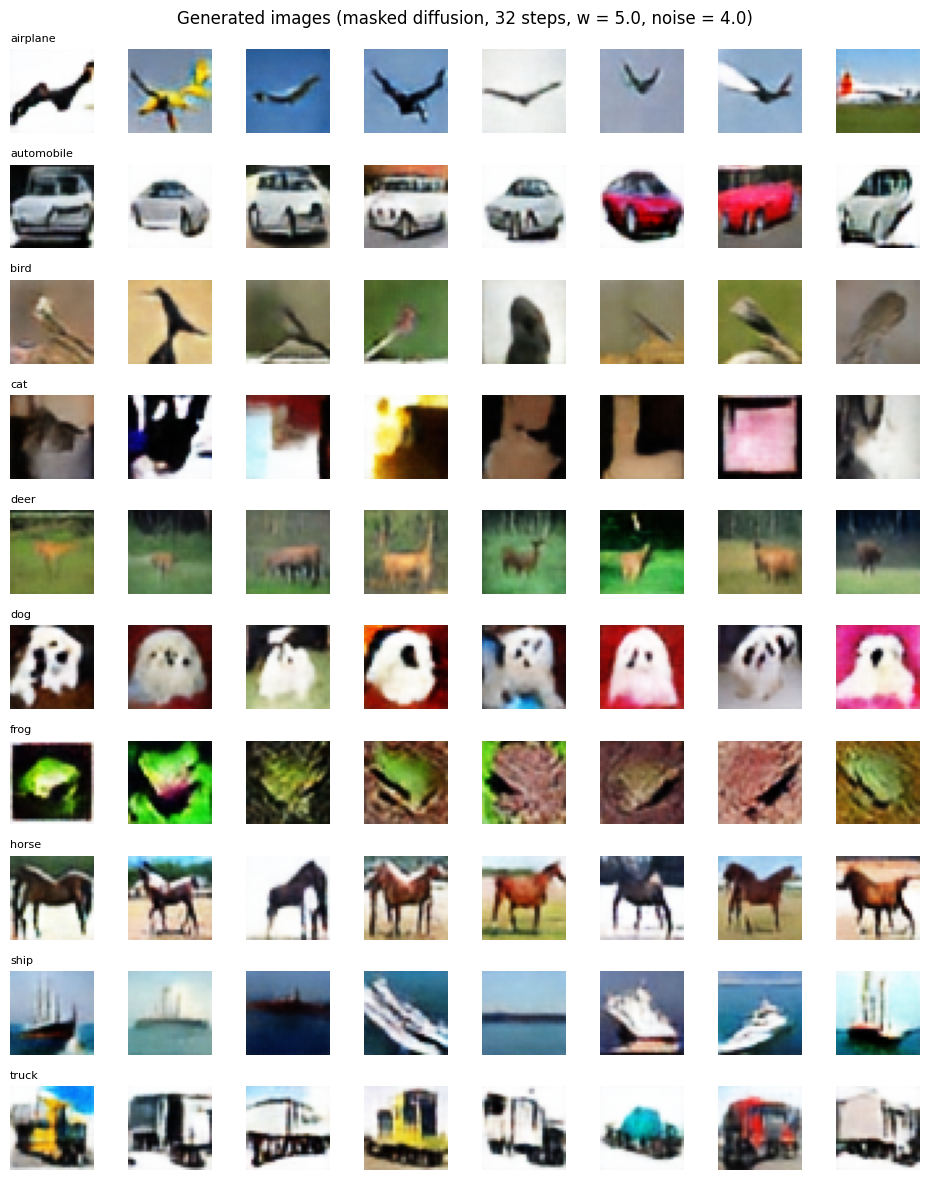

total run time: 1.1 h


In [10]:
CLASSES = ["airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]
torch.manual_seed(0)
labels = torch.arange(NUM_CLASSES).repeat_interleave(8)
imgs = decode(sample(ema, labels, steps=STEPS, w=W, noise=NOISE))
fig, axes = plt.subplots(NUM_CLASSES, 8, figsize=(8 * 1.2, NUM_CLASSES * 1.2))
for i in range(NUM_CLASSES * 8):
    ax = axes[i // 8, i % 8]
    ax.imshow(imgs[i].permute(1, 2, 0).clamp(0, 1)); ax.axis("off")
    if i % 8 == 0:
        ax.set_title(CLASSES[i // 8], loc="left", fontsize=8)
plt.suptitle(f"Generated images (masked diffusion, {STEPS} steps, w = {W}, noise = {NOISE})")
plt.tight_layout(); plt.savefig(f"{SAVE_DIR}/vqdiff_samples_best.png", dpi=120); plt.show()
print(f"total run time: {(time.time() - NOTEBOOK_START) / 3600:.1f} h")